###Name:Sayali Gundawar
###Roll:21
###Batch/Section:B3-B2
Project - Mobile Phone Price Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import f_oneway, pearsonr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, classification_report, confusion_matrix)

1 — DATA LOADING

In [2]:
df = pd.read_csv("mobile_price_dataset.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (15500, 22)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price,price_range
0,2947,1,1.4,1,4,1,64,0.8,127,5,...,1674,964,18,7,6,1,1,0,28600,0
1,5213,1,0.8,1,9,1,512,0.7,160,4,...,691,6398,15,3,5,1,1,1,73200,3
2,4878,1,2.5,0,1,0,32,0.8,85,7,...,963,5451,6,2,12,1,1,1,58500,3
3,1969,0,2.0,0,3,0,512,0.9,198,1,...,1771,3739,11,10,15,1,0,1,54600,2
4,1572,0,2.4,1,12,1,16,0.2,186,7,...,1569,3692,16,5,7,1,1,1,36500,1


2 — DATA CLEANING

In [3]:
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

df.drop_duplicates(inplace=True)
print("Shape after cleaning:", df.shape)

Missing Values: 0
Duplicate Rows: 0
Shape after cleaning: (15500, 22)


PRACTICAL 2 — DATA VISUALIZATION

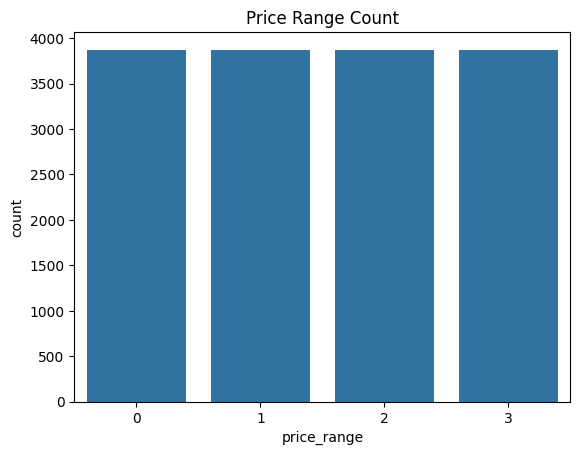

In [4]:
#Count plot of price range
sns.countplot(x="price_range", data=df)

plt.title("Price Range Count")
plt.show()

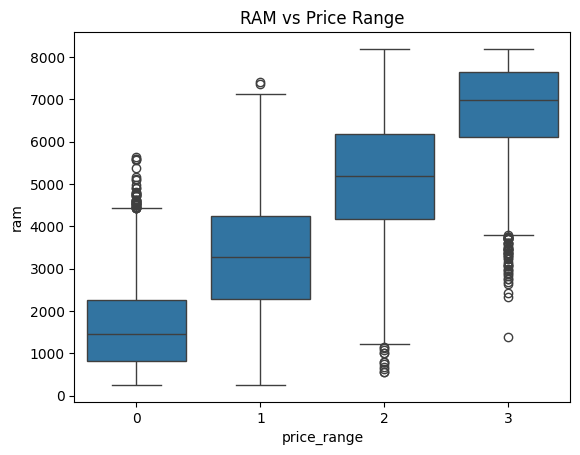

In [5]:
#Box plot of RAM vs price range
sns.boxplot(x="price_range", y="ram", data=df)

plt.title("RAM vs Price Range")
plt.show()

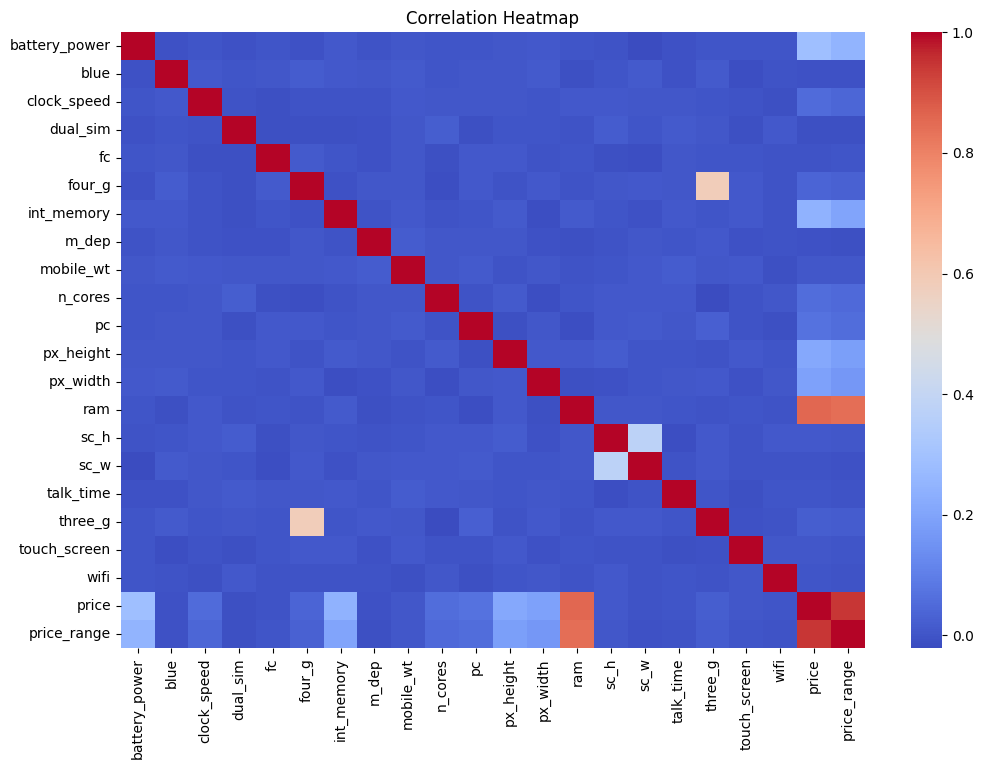

In [6]:
#Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(df.corr(), cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

PRACTICAL 5 & 6 — HYPOTHESIS TESTING (short)

In [7]:
#One-Way ANOVA
groups = [df[df["price_range"] == i]["ram"] for i in range(4)]

f_stat, p_anova = f_oneway(*groups)

print("F-Statistic:", f_stat)
print("P-Value:", p_anova)

if p_anova < 0.05:
    print("Reject H₀: RAM differs significantly across price ranges.")
else:
    print("Fail to Reject H0")

F-Statistic: 12805.584112263232
P-Value: 0.0
Reject H0: RAM price range ke hisaab se significantly alag hai


In [8]:
#Pearson Correlation: RAM vs Price
r, p = pearsonr(df["ram"], df["price"])

print("Correlation:", r)
print("P-Value:", p)

if p < 0.05:
    print("Reject H₀: There is a significant relationship between RAM and Price.")
else:
    print("Fail to Reject H0")

Correlation: 0.8595966950834896
P-Value: 0.0
Reject H0: RAM aur Price ka significant relation hai


PRACTICAL 8
###PART A — MULTIPLE REGRESSION (Predict Price)

In [9]:
X = df.drop(["price", "price_range"], axis=1)
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (12400, 20)
Testing Data: (3100, 20)


In [10]:
#Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
linear_pred = linear_model.predict(X_test_scaled)

#Ridge
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
ridge_pred = ridge_model.predict(X_test_scaled)

#Lasso
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train_scaled, y_train)
lasso_pred = lasso_model.predict(X_test_scaled)

#Decision Tree
tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_model.fit(X_train_scaled, y_train)
tree_pred = tree_model.predict(X_test_scaled)

#Random Forest
forest_model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
forest_model.fit(X_train_scaled, y_train)
forest_pred = forest_model.predict(X_test_scaled)

print("All regression models trained")

All regression models trained


In [11]:
#Compare models
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2 Score": r2_score(actual, predicted)
    }

results_df = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_pred),
    evaluate_model("Ridge Regression", y_test, ridge_pred),
    evaluate_model("Lasso Regression", y_test, lasso_pred),
    evaluate_model("Decision Tree", y_test, tree_pred),
    evaluate_model("Random Forest", y_test, forest_pred)
])

results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1917.871360,2393.459435,0.971002
1,Ridge Regression,1917.857832,2393.437024,0.971002
2,Lasso Regression,1917.842620,2393.425286,0.971002
3,Decision Tree,4613.115637,5700.573962,0.835502
4,Random Forest,3917.449837,4916.934786,0.877620


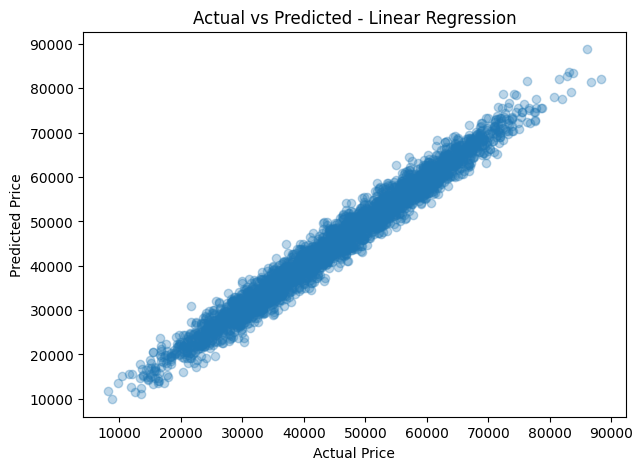

In [12]:
#Actual vs Predicted (Linear Regression)
plt.figure(figsize=(7, 5))

plt.scatter(y_test, linear_pred, alpha=0.3)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted - Linear Regression")

plt.show()

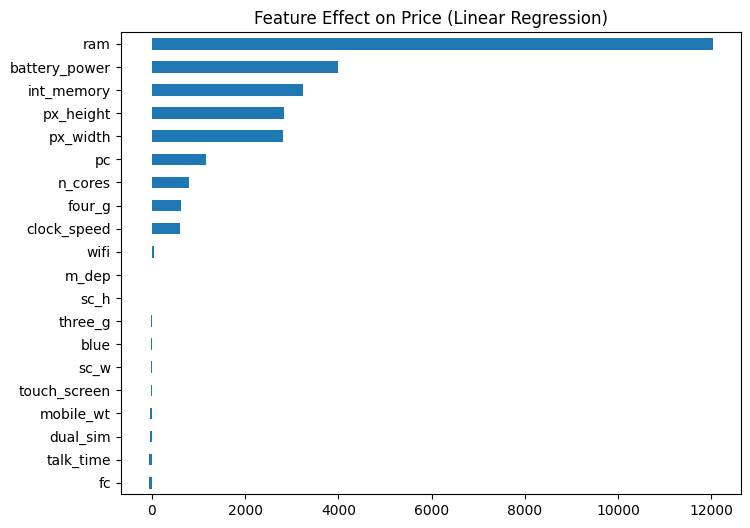

In [13]:
#Coefficients
coef = pd.Series(linear_model.coef_, index=X.columns).sort_values()

coef.plot(kind="barh", figsize=(8, 6))

plt.title("Feature Effect on Price (Linear Regression)")
plt.show()

SAVE REGRESSION MODEL (For price predict )

In [14]:
import joblib

reg_models = {"Linear Regression": linear_model, "Ridge Regression": ridge_model,
              "Lasso Regression": lasso_model, "Decision Tree": tree_model,
              "Random Forest": forest_model}

best_reg_name = results_df.loc[results_df["R2 Score"].idxmax(), "Model"]
best_reg_model = reg_models[best_reg_name]
print("Best Regression Model:", best_reg_name)

joblib.dump(best_reg_model, 'best_reg_model.pkl')
joblib.dump(scaler, 'reg_scaler.pkl')

Best Regression Model: Lasso Regression


['reg_scaler.pkl']

PART B — CLASSIFICATION (Predict Price Range)

In [15]:
X = df.drop(["price", "price_range"], axis=1)
y = df["price_range"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (12400, 20)
Testing Data: (3100, 20)


In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

accuracy = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    accuracy[name] = accuracy_score(y_test, pred)

acc_df = pd.DataFrame({
    "Model": accuracy.keys(),
    "Accuracy": accuracy.values()
})

acc_df

,Model,Accuracy
0,Logistic Regression,0.866129
1,Decision Tree,0.693548
2,Random Forest,0.807742
3,KNN,0.528710


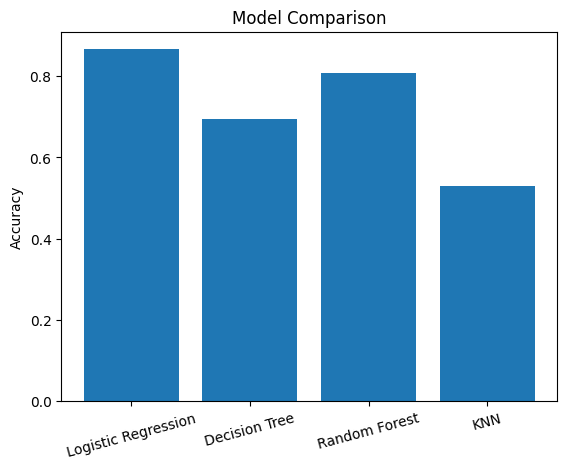

In [17]:
#Model comparison graph
plt.bar(acc_df["Model"], acc_df["Accuracy"])

plt.ylabel("Accuracy")
plt.title("Model Comparison")
plt.xticks(rotation=15)

plt.show()

Best Model: Logistic Regression
              precision    recall  f1-score   support

           0       0.91      0.90      0.91       775
           1       0.81      0.82      0.81       775
           2       0.83      0.82      0.83       775
           3       0.92      0.92      0.92       775

    accuracy                           0.87      3100
   macro avg       0.87      0.87      0.87      3100
weighted avg       0.87      0.87      0.87      3100



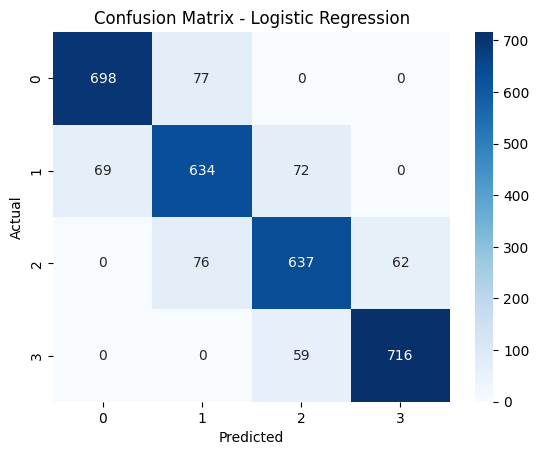

In [18]:
#Best model
best_name = max(accuracy, key=accuracy.get)
best_model = models[best_name]
best_pred = best_model.predict(X_test_scaled)

print("Best Model:", best_name)
print(classification_report(y_test, best_pred))

sns.heatmap(confusion_matrix(y_test, best_pred), annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - " + best_name)

plt.show()

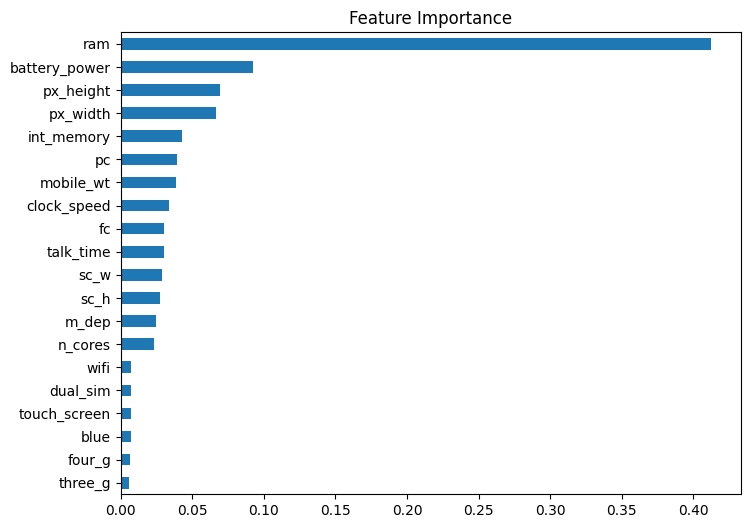

In [19]:
#Feature importance (Random Forest)
rf = models["Random Forest"]

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

imp.plot(kind="barh", figsize=(8, 6))

plt.title("Feature Importance")
plt.show()

CLASSIFICATION MODEL (For price range predict)

In [20]:
joblib.dump(best_model, 'best_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

LOAD MODELS & PREDICT

In [25]:
model = joblib.load('best_model.pkl')
scaler = joblib.load('scaler.pkl')
price_model = joblib.load('best_reg_model.pkl')
price_scaler = joblib.load('reg_scaler.pkl')

def predict_phone(phone):
    range_pred = model.predict(scaler.transform(phone))[0]
    price_pred = price_model.predict(price_scaler.transform(phone))[0]
    return f"Predicted Price Range: {range_pred} | Predicted Price: Rs {int(price_pred)}"

# test
print(predict_phone(X_test.iloc[[0]]))
print("Actual Price Range:", y_test.iloc[0], "| Actual Price:", df.loc[X_test.index[0], "price"])

Predicted Price Range: 0 | Predicted Price: Rs 28297
Actual Price Range: 0 | Actual Price: 26900


In [27]:
# INTERFACE (Gradio)
import gradio as gr

def predict_ui(*vals):
    vals = [int(v) if isinstance(v, bool) else v for v in vals]
    phone = pd.DataFrame([vals], columns=X.columns)
    return predict_phone(phone)

interface = gr.Interface(
    fn=predict_ui,
    inputs=[
        gr.Slider(500, 6000, value=3000, step=1, label="Battery Power (mAh)"),
        gr.Checkbox(label="Bluetooth"),
        gr.Slider(0.5, 3.0, value=1.5, step=0.1, label="Clock Speed (GHz)"),
        gr.Checkbox(label="Dual SIM"),
        gr.Slider(0, 19, value=8, step=1, label="Front Camera (MP)"),
        gr.Checkbox(value=True, label="4G"),
        gr.Dropdown([8, 16, 32, 64, 128, 256, 512], value=64, label="Internal Memory (GB)"),
        gr.Slider(0.1, 1.0, value=0.5, step=0.1, label="Thickness (cm)"),
        gr.Slider(80, 200, value=140, step=1, label="Weight (g)"),
        gr.Slider(1, 8, value=4, step=1, label="Processor Cores"),
        gr.Slider(0, 48, value=12, step=1, label="Primary Camera (MP)"),
        gr.Slider(0, 1999, value=1000, step=1, label="Pixel Height"),
        gr.Slider(500, 1999, value=1200, step=1, label="Pixel Width"),
        gr.Slider(256, 8192, value=4096, step=1, label="RAM (MB)"),
        gr.Slider(5, 19, value=12, step=1, label="Screen Height (cm)"),
        gr.Slider(0, 17, value=6, step=1, label="Screen Width (cm)"),
        gr.Slider(2, 20, value=10, step=1, label="Talk Time (hours)"),
        gr.Checkbox(value=True, label="3G"),
        gr.Checkbox(value=True, label="Touch Screen"),
        gr.Checkbox(label="WiFi"),
    ],
    outputs="text",
    title="Mobile Price Prediction System",
    description="Enter the phone specifications to view the Price Range (0–3) and predicted Price."
)
interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ba589c42dca4cad947.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [23]:
# Colab pkl files
from google.colab import files
for f in ['best_model.pkl', 'scaler.pkl', 'best_reg_model.pkl', 'reg_scaler.pkl']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FINAL RESULT

In [24]:
print("PRACTICAL 8")
print("Part A - Multiple Regression: Completed")
print("Part B - Classification: Completed")

print("\nBest Regression Model:", results_df.loc[results_df["R2 Score"].idxmax(), "Model"])
print("Best Classification Model:", best_name)
print("Best Accuracy:", round(accuracy[best_name], 4))
print("Most Important Feature:", imp.index[-1])

PRACTICAL 8
Part A - Multiple Regression: Completed
Part B - Classification: Completed

Best Regression Model: Lasso Regression
Best Classification Model: Logistic Regression
Best Accuracy: 0.8661
Most Important Feature: ram
